# 04 · Feature Engineering — Schweizer Heizölpreis

Im **Notebook 03** haben wir die Rohdaten (Tagespreise + Nachfrage von heizoel24) erfasst und aufgeräumt.
Hier bauen wir daraus die **Features**, mit denen das Modell den **Preis der nächsten Woche**, den
**Trend (steigend/fallend)** und konkrete **Monatspreise** vorhersagt.

## Anforderung (Aufgabenstellung)

- Mindestens **ein aggregiertes Feature** (Batch / NRT) **und** ein **Echtzeit-Feature (RT)**.
- Ziel: **Preis der nächsten Woche** (Ø der nächsten 7 Tage), **Trend** und — als Zusatz — konkrete
  **Preise für einen spezifischen Monat**.
- Features und Labels müssen **leakage-frei** sein: Features nutzen nur Daten `<= t`, Labels nur `> t`.

## Feature-Architektur (Feature-Store-Konzept)

| Feature | Typ | Bedeutung |
|---|---|---|
| `price_mean_7d` | **aggregiert** | Ø-Preis der letzten 7 Tage |
| `price_std_30d` | **aggregiert** | Volatilität (Std.) der letzten 30 Tage |
| `seasonal_index` | **aggregiert** | Saisonaler Index (trendrobust) |
| `price_mean_dow_4w` | **aggregiert** | Ø desselben Wochentags, letzte 4 Wochen |
| `demand_mean_7d` / `demand_mean_30d` | **aggregiert** | Ø-Nachfrage (heizoel24) |
| `month` / `season` / `month_sin` / `month_cos` | **aggregiert** | saisonale Kodierung |
| `current_price` | **RT** | aktueller Preis (nur zur Inferenz bekannt) |
| `current_demand` | **RT** | aktuelle Nachfrage (heizoel24) |

**Labels:** `target_next_week_price`, `target_week_change`, `target_trend`, `target_next_month_price`.


Zeilen: 8671 | Zeitraum: 2003-01-06 .. 2026-10-02
Im Kalender fehlende Tage (forward-filled): 1643
Spalten: ['price', 'demand']


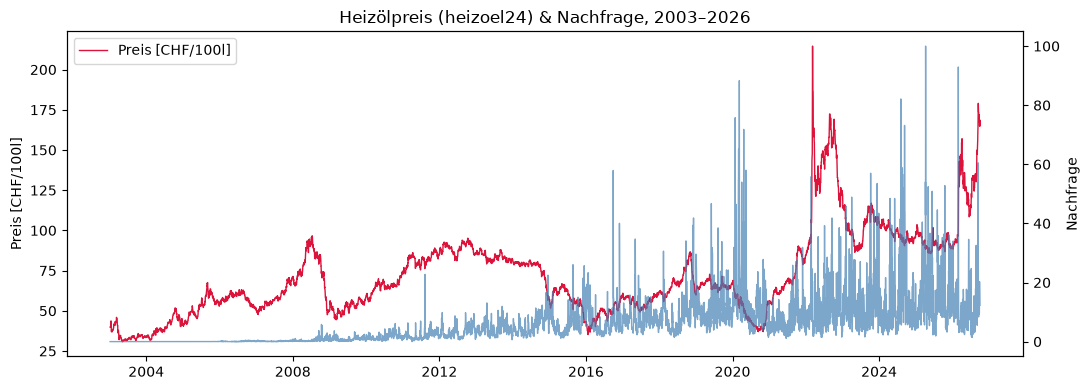

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (11, 4)

# Rohdaten laden (funktioniert aus Repo-Root oder notebooks/)
csv_path = os.path.join("data", "heizoel24_heizoel_daily_ch_full.csv")
if not os.path.exists(csv_path):
    csv_path = os.path.join("..", "data", "heizoel24_heizoel_daily_ch_full.csv")

# Repo-Root robust bestimmen (CSV liegt unter <root>/data/...)
REPO_ROOT = os.path.dirname(os.path.dirname(os.path.abspath(csv_path)))
data_dir = os.path.join(REPO_ROOT, "data")

df = pd.read_csv(csv_path)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date").set_index("date")

# Auf vollen Tageskalender ausdehnen + fehlende Tage (WE/Feiertage) forward-fillen
full = pd.date_range(df.index.min(), df.index.max(), freq="D")
s = df.reindex(full)
s.index.name = "date"
n_filled = int(s["price"].isna().sum())
s["price"] = s["price"].ffill()
s["demand"] = s["demand"].ffill()

print(f"Zeilen: {len(s)} | Zeitraum: {s.index.min().date()} .. {s.index.max().date()}")
print(f"Im Kalender fehlende Tage (forward-filled): {n_filled}")
print("Spalten:", s.columns.tolist())

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(s.index, s["price"], color="crimson", lw=1, label="Preis [CHF/100l]")
ax1.set_ylabel("Preis [CHF/100l]")
ax2 = ax1.twinx()
ax2.plot(s.index, s["demand"], color="steelblue", lw=1, alpha=0.7, label="Nachfrage")
ax2.set_ylabel("Nachfrage")
ax1.set_title("Heizölpreis (heizoel24) & Nachfrage, 2003–2026")
ax1.legend(loc="upper left")
fig.tight_layout()
plt.show()


## 1 · Aggregierte Features (Batch / NRT)

Aggregierte Features fassen **mehrere Zeitpunkte** zu einem Wert zusammen (Fenster- oder
Gruppenoperationen). Sie werden im **Batch-Feature-Pipeline** (Hopsworks Jobs/Pipelines) berechnet und
als **Offline-Features** im Feature Store abgelegt. Die Aufgabenstellung verlangt explizit diese vier:

1. **7-Tage-Mittelwert** → `price_mean_7d`
2. **30-Tage-Volatilität** → `price_std_30d` (Standardabweichung)
3. **Saisonaler Index** → `seasonal_index` (Ø-Monat / Ø-Jahr, über alle Jahre gemittelt → robust gegen Trend)
4. **Wochentags-Mittelwert** → `price_mean_dow_4w` (Ø desselben Wochentags, letzte 4 Wochen)

Dazu fassen wir die **heizoel24-Nachfrage** zusammen (`demand_mean_7d`, `demand_mean_30d`) und ergänzen
saisonale Kodierungen (`month`, `season`, `month_sin/cos`). Alle Features nutzen **nur Daten bis t**.


In [2]:
p = s["price"]

# 1) 7-Tage-Mittelwert
s["price_mean_7d"] = p.rolling(7, min_periods=1).mean()
# 2) 30-Tage-Volatilität (Standardabweichung)
s["price_std_30d"] = p.rolling(30, min_periods=7).std()
# 3) Nachfrage (heizoel24) aggregiert
s["demand_mean_7d"]  = s["demand"].rolling(7,  min_periods=1).mean()
s["demand_mean_30d"] = s["demand"].rolling(30, min_periods=7).mean()

# 4) Saisonaler Index + saisonale Kodierung
month = s.index.month
s["month"] = month
s["season"] = month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Frühling", 4: "Frühling", 5: "Frühling",
    6: "Sommer", 7: "Sommer", 8: "Sommer",
    9: "Herbst", 10: "Herbst", 11: "Herbst",
})
s["month_sin"] = np.sin(2 * np.pi * month / 12)
s["month_cos"] = np.cos(2 * np.pi * month / 12)

# trendrobuster saisonaler Index: (Ø Monat / Ø Jahr) pro (Jahr, Monat), dann über alle Jahre gemittelt
_ym = pd.DataFrame({"year": s.index.year, "month": s.index.month, "price": s["price"].values})
_ym_mean = _ym.groupby(["year", "month"])["price"].mean().reset_index()
_ym_mean["ratio"] = _ym_mean["price"] / _ym_mean["year"].map(_ym.groupby("year")["price"].mean())
_seasonal_idx = _ym_mean.groupby("month")["ratio"].mean()
s["seasonal_index"] = month.map(_seasonal_idx)

# 5) Wochentags-Mittelwert: Ø desselben Wochentags, letzte 4 Wochen
s["price_mean_dow_4w"] = (p.shift(7) + p.shift(14) + p.shift(21) + p.shift(28)) / 4

print("Saisonaler Index (1.0 = Jahres-Ø; >1 teurer, <1 billiger):")
print(_seasonal_idx.round(3).to_string())
print("\nLetzte 3 Zeilen (aggregierte Features):")
print(s[["price", "price_mean_7d", "price_std_30d", "seasonal_index", "price_mean_dow_4w", "demand_mean_7d"]].tail(3).round(3).to_string())


Saisonaler Index (1.0 = Jahres-Ø; >1 teurer, <1 billiger):
month
1     0.948
2     0.957
3     1.004
4     0.993
5     0.984
6     0.992
7     1.000
8     1.013
9     1.039
10    1.060
11    1.025
12    0.997

Letzte 3 Zeilen (aggregierte Features):
             price  price_mean_7d  price_std_30d  seasonal_index  price_mean_dow_4w  demand_mean_7d
date                                                                                               
2026-09-30  167.87        167.863         10.262           1.039            163.715          16.301
2026-10-01  168.63        167.539          9.666           1.060            163.010          15.841
2026-10-02  164.89        167.136          9.301           1.060            162.760          14.848


## 2 · Echtzeit-Features (RT)

Echtzeit-Features sind **nur zur Inferenzzeit** bekannt und werden zur Vorhersage (bzw. Order-Entscheidung)
per API abgefragt — sie stehen im **Online Store**. Für das Training rekonstruieren wir sie aus der Historie.

- `current_price` — der Preis **am Tag t** (bekannt, wenn zur Inferenz entschieden wird).
- `current_demand` — die **aktuelle Nachfrage** von heizoel24 am Tag t.

> **Warum Nachfrage ein echtes RT-Feature?** heizoel24 liefert pro Tag die aktuelle Nachfrage. Steigt die
> Nachfrage (Kälteeinbruch, Herbst-Vorratskauf), steigen tendenziell auch die **effektiven Tagespreise** —
> gerade wenn die **Bestellung zum Tagespreis** ausgelöst werden soll. `current_demand` beeinflusst daher
> die **Order-Timing-Entscheidung** direkt und wird zur Inferenz live abgefragt.


In [3]:
# RT-Features: bekannt nur zur Inferenzzeit (Online Store); hier aus Historie rekonstruiert
s["current_price"]  = p            # Preis am Tag t
s["current_demand"] = s["demand"]  # aktuelle heizoel24-Nachfrage am Tag t

print("RT-Features (letzte 3 Zeilen):")
print(s[["current_price", "current_demand"]].tail(3).round(3).to_string())


RT-Features (letzte 3 Zeilen):
            current_price  current_demand
date                                     
2026-09-30         167.87          16.310
2026-10-01         168.63          15.755
2026-10-02         164.89          12.278


## 3 · Target (Labels)

Das Modell soll für **jeden Zeitpunkt t** den darauffolgenden Zeitraum vorhersagen:

| Label | Art | Bedeutung |
|---|---|---|
| `target_next_week_price` | Regression | Ø-Preis der **nächsten 7 Tage** (t+1 … t+7) |
| `target_week_change` | Regression | `target_next_week_price − current_price` (erwartete Änderung) |
| `target_trend` | Classification | **1** = steigend, **0** = fallend (Bezug: aktueller Preis) |
| `target_next_month_price` | Regression | Ø-Preis des **nächsten Kalendermonats** (spezifischer Monat, parametrisierbar) |

Wichtig: Alle Labels verwenden **nur Zukunft** (t+1 …). Alle Features nutzen **nur <= t** → **kein Leakage**.


Label-Verteilung:
  target_trend: steigend = 50.85% | fallend = 49.15%
  target_next_week_price: Ø 71.7 (Min 31.0, Max 192.9)
  target_week_change: Ø 0.06 CHF/100l


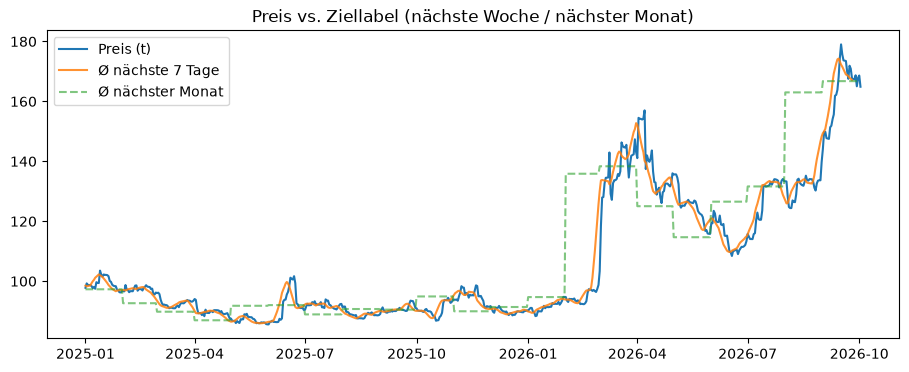

In [4]:
# Ø der nächsten 7 Tage: rolling(7) am Index t+7 = Ø(t+1..t+7); shift(-7) -> Ziel am Index t
_rolling7 = p.rolling(7, min_periods=7).mean()
s["target_next_week_price"] = _rolling7.shift(-7)
s["target_week_change"] = s["target_next_week_price"] - s["current_price"]
s["target_trend"] = (s["target_week_change"] > 0).astype(int)

# konkreter Preis für einen spezifischen Monat (hier: nächster Kalendermonat)
_month_avg = s["price"].groupby(s.index.to_period("M")).mean()
s["target_next_month_price"] = (s.index.to_period("M") + 1).map(_month_avg)

print("Label-Verteilung:")
print(f"  target_trend: steigend = {s['target_trend'].mean():.2%} | fallend = {1 - s['target_trend'].mean():.2%}")
print(f"  target_next_week_price: Ø {s['target_next_week_price'].mean():.1f} "
      f"(Min {s['target_next_week_price'].min():.1f}, Max {s['target_next_week_price'].max():.1f})")
print(f"  target_week_change: Ø {s['target_week_change'].mean():.2f} CHF/100l")

tail = s["2025":]
plt.plot(tail.index, tail["price"], label="Preis (t)")
plt.plot(tail.index, tail["target_next_week_price"], label="Ø nächste 7 Tage", alpha=0.85)
plt.plot(tail.index, tail["target_next_month_price"], label="Ø nächster Monat", alpha=0.6, linestyle="--")
plt.legend()
plt.title("Preis vs. Ziellabel (nächste Woche / nächster Monat)")
plt.show()


In [5]:
# FEATURE + LABEL DATENFRAME  (Grundlage für die Feature Group im Feature Store)
AGG_FEATURES = [
    "price_mean_7d", "price_std_30d",
    "demand_mean_7d", "demand_mean_30d",
    "month", "season", "month_sin", "month_cos", "seasonal_index", "price_mean_dow_4w",
]
RT_FEATURES = ["current_price", "current_demand"]
LABELS = ["target_next_week_price", "target_week_change", "target_trend", "target_next_month_price"]
FEATURES = AGG_FEATURES + RT_FEATURES

# Zeilen mit NaN verwerfen (Start: 30d-Fenster + 4w-Wochentag; Ende: 7d-Ziel)
dataset = s[FEATURES + LABELS].dropna().reset_index()

print("Feature+Label-Datensatz:", dataset.shape)
print("Aggregierte Features:", AGG_FEATURES)
print("RT-Features:", RT_FEATURES)
print("Labels:", LABELS)
print("\nHead:")
_h = dataset.head(3)
_num = _h.select_dtypes("number").columns
print(_h.assign(**{c: _h[c].round(3) for c in _num}).to_string())


Feature+Label-Datensatz: (8636, 17)
Aggregierte Features: ['price_mean_7d', 'price_std_30d', 'demand_mean_7d', 'demand_mean_30d', 'month', 'season', 'month_sin', 'month_cos', 'seasonal_index', 'price_mean_dow_4w']
RT-Features: ['current_price', 'current_demand']
Labels: ['target_next_week_price', 'target_week_change', 'target_trend', 'target_next_month_price']

Head:
        date  price_mean_7d  price_std_30d  demand_mean_7d  demand_mean_30d  month  season  month_sin  month_cos  seasonal_index  price_mean_dow_4w  current_price  current_demand  target_next_week_price  target_week_change  target_trend  target_next_month_price
0 2003-02-03         37.949          2.236             0.0              0.0      2  Winter      0.866        0.5           0.957             39.582          37.97             0.0                  38.859               0.889             1                   41.823
1 2003-02-04         38.007          2.205             0.0              0.0      2  Winter      0.866     

## 4 · Überführung in den Feature Store (Hopsworks)

Der Datensatz `dataset` hat exakt die Struktur, die als **Feature Group** in Hopsworks registriert wird.

| Feld | Wert |
|---|---|
| Feature Group | `heizoel24_daily_features` |
| **Primärschlüssel** | `date` (unique ID der Zeile) |
| **Event Time** | `date` |
| Aggregierte Features (Batch / Offline) | `price_mean_7d`, `price_std_30d`, `seasonal_index`, `price_mean_dow_4w`, `demand_mean_*`, … |
| RT-Features (Online) | `current_price`, `current_demand` |

Die **aggregierten Features** werden im Batch-Feature-Pipeline (Hopsworks) als **Offline-Features**
berechnet/abgelegt. Die **RT-Features** werden zur Inferenzzeit über eine API aus dem **Online Store**
geliefert (bzw. bei jeder Order-Entscheidung neu abgefragt).


In [ ]:
# 1) Lokal speichern (reproduzierbar, ohne Cloud)
out_dir = os.path.join(data_dir, "features")
os.makedirs(out_dir, exist_ok=True)
local_csv = os.path.join(out_dir, "heizoel24_features.csv")
dataset.to_csv(local_csv, index=False)
print(f"Gespeichert: {local_csv}  ({len(dataset)} Zeilen, {len(dataset.columns)} Spalten)")

# 2) Feature Store: Parquet auf S3 (Rook Ceph) hochladen
#    Das Training (06_training_pipeline.ipynb / src/training_pipeline.py) laedt genau diesen Pfad:
#    s3://oilprice-features/processed_features.parquet
import os
import sys
import tempfile

import s3fs

sys.path.insert(0, os.path.abspath("../src"))  # notebooks/ -> src/

from s3_credentials import get_s3_options

FEATURES_S3_PATH = "s3://oilprice-features/processed_features.parquet"

try:
    # Credentials kommen aus der Umgebung (Cluster: secretKeyRef "s3-credentials",
    # lokal: .env). Kein kubectl, kein base64, keine Credentials im Notebook.
    # s3fs liest KEINE FSSPEC_S3_*-Umgebungsvariablen: Credentials explizit uebergeben:
    # https://s3fs.readthedocs.io/en/latest/index.html#s3-compatible-storage
    s3_options = get_s3_options()

    s3 = s3fs.S3FileSystem(**s3_options)
    tmp_parquet = os.path.join(tempfile.gettempdir(), "processed_features.parquet")
    dataset.to_parquet(tmp_parquet, index=False)
    s3.put_file(tmp_parquet, FEATURES_S3_PATH)
    print(f"Feature Store (S3): {FEATURES_S3_PATH}  ({len(dataset)} Zeilen, {len(dataset.columns)} Spalten)")
except Exception as e:
    print(f"S3-Upload nicht moeglich ({type(e).__name__}: {e}).")
    print("=> Lokale CSV bleibt erhalten; S3-Feature Store nicht aktualisiert.")
    print("Lokal: .env.example nach .env kopieren (AWS_ACCESS_KEY_ID /")
    print("AWS_SECRET_ACCESS_KEY / AWS_ENDPOINT_URL) und die Zelle erneut ausfuehren.")


## 5 · Welche Daten können wir noch heranziehen?

Kernaussage: Die **heizoel24-Nachfrage** (`current_demand`, `demand_mean_*`) ist bereits eingebaut und
wichtig, weil sie die **Order-Entscheidung zum Tagespreis** direkt beeinflusst. Darüber hinaus sind diese
externen Quellen sinnvoll — sie liefern unabhängige, kausale Signale für den Heizölpreis:

| Quelle | Signal | Typ | Warum relevant |
|---|---|---|---|
| **Nachfrage (heizoel24)** | aktuelle Nachfrage | RT + aggregiert | Treiber des effektiven Tagespreises; Order-Timing |
| **Wetter (Open-Meteo)** | Temperatur, Kälte | RT (Vorhersage) + aggregiert | Kälte ⇒ mehr Heiznachfrage ⇒ Preis↑; stärkstes Saison-Signal |
| **Rohöl (Brent/WTI)** | Benchmark-Preis | RT + aggregiert | Heizöl = destilliertes Erdöl; folgt Rohöl (commodities-api.com `HOU22`) |
| **Devisen (USD/CHF)** | FX-Kurs | RT | Rohöl in USD, CH-Preis in CHF → FX wirkt direkt |
| **Gas (TTF)** | Gas-Preis | RT + aggregiert | Gas als Substitut; beeinflusst Preis/Nachfrage |
| **LIK (BFE)** | Treibstoffpreis-Index | aggregiert | offizieller CH-Benchmark (energiedashboard.ch) |

Fast alle Quellen lassen sich **aggregiert** (z. B. 7-/30-Tage-Ø) und **als RT** (aktueller Stand)
erfassen — genau die beiden Feature-Typen, die wir benötigen. **Wetter** (2. Datenquelle) wird im
nächsten Abschnitt als aggregiertes Feature demonstrativ eingebaut.


Wetter geladen: 8671 Tage, Ø 10.4 °C
Korrelation (7-Tage-Ø Temperatur, Preis): 0.103


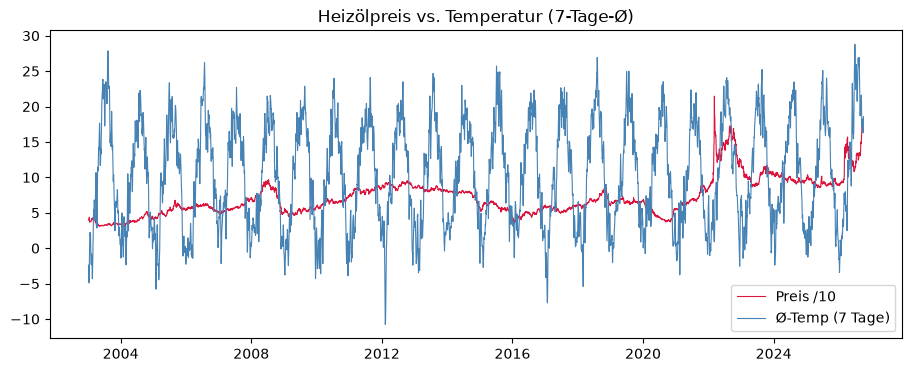

In [7]:
# Zweite Datenquelle (Wetter, Open-Meteo) als aggregiertes Feature.
# try/except => das Notebook bleibt ohne Internet robust.
try:
    import requests
    r = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 47.3769, "longitude": 8.5417,   # Zürich (repräsentativ für CH)
            "daily": "temperature_2m_mean",
            "start_date": str(s.index.min().date()),
            "end_date": str(s.index.max().date()),
            "timezone": "auto",
        },
        timeout=60,
    )
    r.raise_for_status()
    d = r.json()["daily"]
    temp = (
        pd.Series(d["temperature_2m_mean"], index=pd.to_datetime(d["time"]))
        .reindex(s.index)
        .ffill()
    )
    s["temp_mean_7d"] = temp.rolling(7, min_periods=1).mean()   # aggregiert (2. Quelle)
    s["temp_current"] = temp                                     # RT (aktueller Stand)

    print(f"Wetter geladen: {int(temp.notna().sum())} Tage, Ø {temp.mean():.1f} °C")
    print("Korrelation (7-Tage-Ø Temperatur, Preis):",
          round(s[["temp_mean_7d", "price"]].corr().iloc[0, 1], 3))

    plt.figure(figsize=(11, 4))
    plt.plot(s.index, s["price"] / 10, color="crimson", lw=0.8, label="Preis /10")
    plt.plot(s.index, s["temp_mean_7d"], color="steelblue", lw=0.8, label="Ø-Temp (7 Tage)")
    plt.legend()
    plt.title("Heizölpreis vs. Temperatur (7-Tage-Ø)")
    plt.show()
except Exception as e:
    print(f"Wetter-Quelle nicht verfügbar ({type(e).__name__}: {e}).")
    print("=> Wetter-Features werden übersprungen; Kern-Features bleiben unverändert.")


## 6 · Reflexion & Limitationen

**Erledigt (Feature Engineering):**
- Kern-Features aus der heizoel24-Quelle (Preis + Nachfrage) mit **aggregierten** und **RT**-Features.
- Alle vier geforderten aggregierten Features: 7d-Mittel, 30d-Volatilität, saisonaler Index, Wochentags-Mittel.
- Labels: nächster-Wochen-Preis, Trend, konkreter Monatspreis — **leakage-frei** (Features <= t, Labels > t).
- **Wetter (Open-Meteo)** als zweite Datenquelle demonstrativ als aggregiertes Feature (7-Tage-Ø) ergänzt.
- `dataset` ist direkt als **Feature Group** nutzbar (PK/Event-Time = `date`), lokal gespeichert + optional Hopsworks.

**Limitationen:**
- **Unoffizielle API:** Der heizoel24-Endpoint ist nicht dokumentiert/stabil — im Produktivbetrieb durch
  eigenen Scraper + eigene DB ersetzen (vgl. TODO.md).
- **Nachfrage in frühen Jahren = 0:** `demand` ist bis ~2005 nicht verfügbar (0). Daraus resultierende
  0-Features sind ein Datenqualitäts-Problem; im Training ggf. auf den Zeitraum ab ~2005 beschränken oder
  die 0er als "unbekannt" behandeln.
- **Saisonaler Index:** trendrobust berechnet (Monat/Jahr), aber über 2003–2026 gemittelt — der 2022er
  Energiekrise-Preis und der Langfrist-Trend prägen den Index. Kürzere Fenster sind möglich.
- **Einzelne Datenquelle für Kern:** Preis + Nachfrage stammen von heizoel24; unabhängige Quellen
  (Wetter/Rohöl/FX) sind als Demo eingebaut, aber nicht im Kern-`dataset`.
- **"Spezifischer Monat":** hier = nächster Kalendermonat; ein beliebiges Zielmonat (z. B. "Preis von
  Dezember") ist leicht parametrisierbar.
